In [1]:
import torch
import numpy as np

a = [1,2,3]
b = np.array ([4,5,6], dtype = np.int32)
t_a = torch.tensor(a)
t_b = torch.from_numpy(b)
print(t_a)
print(t_b)

tensor([1, 2, 3])
tensor([4, 5, 6], dtype=torch.int32)


In [2]:
t_ones = torch.ones(2,3)
print(t_ones)
t_ones.shape

tensor([[1., 1., 1.],
        [1., 1., 1.]])


torch.Size([2, 3])

In [3]:
rand_tensor = torch.rand(2,3)
rand_tensor

tensor([[0.5427, 0.9269, 0.7520],
        [0.4313, 0.7018, 0.5789]])

In [4]:
t_a_n = t_a.to(torch.int64) #changes the dtype of a tensor
print(t_a_n)

tensor([1, 2, 3])


In [5]:
t = torch.rand(3,5)
t_tr = torch.transpose(t, 0, 1)
print(t.shape, '-->', t_tr.shape)

torch.Size([3, 5]) --> torch.Size([5, 3])


In [6]:
t = torch.zeros(30)
t_reshape = t.reshape(5,6)
print(t.shape, t_reshape.shape)
print(t, '\n', t_reshape)

torch.Size([30]) torch.Size([5, 6])
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.]) 
 tensor([[0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0.]])


In [7]:
t = torch.zeros(1,2,1,4,1)
t_sqz = torch.squeeze(t,2)
print(f'{t.shape}:\n{t}, \n {t_sqz.shape}:\n{t_sqz}')

torch.Size([1, 2, 1, 4, 1]):
tensor([[[[[0.],
           [0.],
           [0.],
           [0.]]],


         [[[0.],
           [0.],
           [0.],
           [0.]]]]]), 
 torch.Size([1, 2, 4, 1]):
tensor([[[[0.],
          [0.],
          [0.],
          [0.]],

         [[0.],
          [0.],
          [0.],
          [0.]]]])


In [8]:
import torch


with open("data/input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print(len(text))



print(text[:500])



chars = sorted(set(text))
vocab_size = len(chars)
print(vocab_size)
print("".join(chars))



str_to_int = {ch: i for i,ch in enumerate(chars)}
int_to_str = {i: ch for ch, i in str_to_int.items()}

def encode(s):
    return [str_to_int[c] for c in s]

def decode(ids):
    return "".join(int_to_str[i] for i in ids)

print(encode("hello"))
print(decode(encode("hello")))

data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:100])





1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor
65

 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
[46, 43, 50, 50, 53]
hello
torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  

In [9]:
from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

full_train = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="data", train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.34MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 13.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.03MB/s]


In [11]:
from torch.utils.data import random_split, DataLoader

train_set, val_set = random_split(
    full_train, [55000, 5000],
    generator=torch.Generator().manual_seed(42)
    )

In [12]:
train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
val_loader = DataLoader(val_set, batch_size = 256, shuffle=False)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

In [13]:
images, labels = next(iter(train_loader))
print(images.shape, images.dtype)
print(labels.shape, labels.dtype)
print(images[:10])
print(labels[:10])

torch.Size([64, 1, 28, 28]) torch.float32
torch.Size([64]) torch.int64
tensor([[[[-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          ...,
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242]]],


        [[[-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          ...,
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242],
          [-0.4242, -0.4242, -0.4242,  ..., -0.4242, -0.4242, -0.4242]]],


        [[[-0.4242, -0.4242

In [16]:
import torch.nn as nn

In [14]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


In [22]:
class Model(nn.Module):
    def __init__(self, n_features = 1*28*28, n_hidden = 128, num_classes = 10):
        super().__init__()
        self.flatten = nn.Flatten()
        self.relu = nn.ReLU()

        self.w1 = nn.Parameter(torch.empty((n_hidden, n_features)))
        self.b1 = nn.Parameter(torch.empty((n_hidden,)))

        self.w2 = nn.Parameter(torch.empty((num_classes, n_hidden)))
        self.b2 = nn.Parameter(torch.empty((num_classes,)))

        self.reset_parameters()

    def reset_parameters(self):
        nn.init.kaiming_normal_(self.w1, mode="fan_in", nonlinearity="relu")
        nn.init.zeros_(self.b1)

        nn.init.kaiming_normal_(self.w2, mode="fan_in", nonlinearity="linear")
        nn.init.zeros_(self.b2)

    def forward(self, x):
        x = self.flatten(x)

        z1 = (x @ self.w1.T) + self.b1

        h = self.relu(z1)

        z2 = (h @ self.w2.T) + self.b2

        return z2   



In [28]:
import torch.optim as optim
model = Model().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr = 0.01, momentum=0.9)
num_epochs = 10

losses = []
val_losses = []

for epoch in range(num_epochs):
    running_tot = 0
    model.train()
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = criterion(logits, labels)
        running_tot += loss.item() * images.size(0)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        
    losses.append(running_tot / len(train_loader.dataset))

    model.eval()
    with torch.no_grad():
        val_loss_totals = 0
        val_total = 0
        correct = 0
        for val_images, val_labels in val_loader:
            val_images = val_images.to(device)
            val_labels = val_labels.to(device)

            val_logits = model(val_images)
            val_loss = criterion(val_logits, val_labels)
            val_loss_totals += val_loss.item() * val_images.size(0)

            pred = val_logits.argmax(dim=1)
            correct += (pred == val_labels).sum().item()
            val_total += val_labels.size(0)
        val_losses.append(val_loss_totals / val_total)


    acc = (correct / val_total) * 100
    print(f'Epoch {epoch}: Model Accuracy: {acc:.3f}')


Epoch 0: Model Accuracy: 95.260
Epoch 1: Model Accuracy: 96.220
Epoch 2: Model Accuracy: 96.640
Epoch 3: Model Accuracy: 97.020
Epoch 4: Model Accuracy: 97.180
Epoch 5: Model Accuracy: 96.980
Epoch 6: Model Accuracy: 97.340
Epoch 7: Model Accuracy: 97.260
Epoch 8: Model Accuracy: 97.280
Epoch 9: Model Accuracy: 97.300


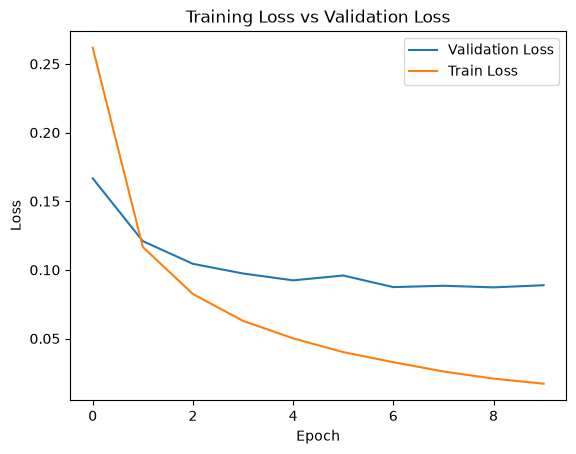

In [29]:
import matplotlib.pyplot as plt

plt.plot(val_losses, label='Validation Loss')
plt.plot(losses, label = 'Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss vs Validation Loss')
plt.legend()
plt.show()

In [33]:
test_loss_total = 0
test_correct = 0
test_total = 0
for test_images, test_labels in test_loader:
    model.eval()
    with torch.no_grad():
        test_images, test_labels = test_images.to(device), test_labels.to(device)

        test_logits = model(test_images)
        test_loss = criterion(test_logits, test_labels)
        test_loss_total += test_loss.item() * test_images.size(0)
        test_pred = test_logits.argmax(dim=1)
        test_correct += (test_pred == test_labels).sum().item()
        test_total += test_labels.size(0)

test_loss_val = test_loss_total / test_total
test_acc = (test_correct / test_total) * 100
print(f'Test Loss: {test_loss_val}\nTest Accuracy: {test_acc}')


    


Test Loss: 0.075122482635919
Test Accuracy: 98.09


In [62]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

X,y = fetch_california_housing(return_X_y=True)
housing = fetch_california_housing(as_frame=True)
housing_data = housing.frame
housing_data.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [63]:
display(X.shape, y.shape)

(20640, 8)

(20640,)

In [64]:
X = torch.from_numpy(X)
X = X.to(torch.float32)
y = torch.from_numpy(y)
y = y.to(torch.float32)

In [65]:
from torch.utils.data import TensorDataset, random_split, DataLoader
n_samples = X.shape[0]

generator = torch.Generator().manual_seed(42)
indices = torch.randperm(n_samples, generator=generator)
train_end = int(n_samples * 0.80)
val_end = train_end + int(n_samples * 0.10)

train_ind = indices[:train_end]
val_ind = indices[train_end:val_end]
test_ind = indices[val_end:]

X_train, y_train = X[train_ind], y[train_ind]
X_val, y_val = X[val_ind], y[val_ind]
X_test, y_test = X[test_ind], y[test_ind]


torch.Size([16512, 8]) 
 torch.Size([16512])


In [73]:
X_train_mean = X_train.mean(dim=0, keepdim=True)
X_train_std = X_train.std(dim=0, keepdim=True).clamp(min=1e-6)


X_norm_train = (X_train - X_train_mean) / X_train_std
X_norm_val = (X_val - X_train_mean) / X_train_std
X_norm_test = (X_test - X_train_mean) / X_train_std

In [75]:
X_norm_train.mean()

tensor(-1.9597e-07)

In [76]:
train_loader = DataLoader(TensorDataset(X_norm_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_norm_val, y_val), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(X_norm_test, y_test), batch_size=64, shuffle=False)

In [ ]:
class housing_model(nn.Linear):
    def__init__():
    